# SLU16 - Workflow: Exercise Notebook

In [1]:
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn import linear_model
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.base import TransformerMixin
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

import hashlib # just for grading purposes
import json # just for grading purposes

from utils import workflow_steps, data_analysis_steps
from utils import get_dataset
from utils import plot_confusion_matrix

<div class="alert alert-info">
    A <b>data science workflow</b> defines the phases (or steps) in a data science project. Using a well-defined data science workflow is useful not only to you, but also to your teammates as it provides a simple way to clearly structure and organize a data science project. Across this specialization we've been covering the different steps in this workflow, but how well are you familiarised with them?
</div>

## Exercise 1: Workflow

### Exercise 1.1 - Overall workflow steps

What are the basic workflow steps?

You probably know them already, but we want you to really internalize them. We've given you a list of steps in `workflow_steps`, but it appears that, not only does it have too many steps, some are _probably_ wrong, as well.

Listed below are several steps that might be part of a machine learning workflow. Some of these steps are essential, some are substeps of broader categories, and others are not relevant at all. Your task is to filter out the irrelevant steps, identify which are major/principal steps and arrange them in a logical order.

The answer should be a list of the workflow names as shown below.
```python
workflow_steps_answer_EXAMPLE = ['Google Hackathon solutions',  'Train model', 'Watch Netflix','Iterate']
```

In [2]:
print("Workflow steps:")
for i in range(len(workflow_steps)):
    print(i+1, ': ', workflow_steps[i])

Workflow steps:
1 :  Get the data
2 :  Watch Netflix
3 :  Google Hackathon solutions
4 :  Train model
5 :  Evaluate results
6 :  Establish a Baseline
7 :  Spam
8 :  Data analysis and preparation
9 :  Iterate
10 :  Increase complexity


In [3]:
# Exercise 1.1. Filter and sort the names of the steps in the workflow_steps list
# workflow_steps_answer = [...]

# YOUR CODE HERE
workflow_steps_answer = [
    'Get the data',
    'Data analysis and preparation',
    'Train model',
    'Evaluate results',
    'Iterate'
]

In [4]:
assert hashlib.sha256(json.dumps(str(len(workflow_steps_answer))).encode()).hexdigest() == \
'd10a4bc9e0c1fa4e8f3d7ce2512b8756e47ca5fa451f373c39a1431bb88db49f', "your workflow size doesn't look right! Don't forget to remove steps that shouldn't be there"
assert hashlib.sha256(json.dumps(''.join(workflow_steps_answer)).encode()).hexdigest() == \
'f52fdbe9d46026f357ca8077b5b522e2ff03d1d6406bcbcded01e51cbb1c7407', "Your workflow order doesn't look right! Some steps might be out of place."

### Exercise 1.2: Data Analysis and Preparation

There are way too many substeps in the **Data Analysis and Preparation** step to group them all under a single category. We've given you another list of steps: `data_analysis_steps`.

Aside from being shuffled it should be fine, but keep an eye out. You never know what to expect...

In [5]:
print("Data Analysis and Preparation steps:")
for i in range(len(data_analysis_steps)):
    print(i+1, ': ', data_analysis_steps[i])

Data Analysis and Preparation steps:
1 :  Spanish Inquisition
2 :  Dealing with data problems
3 :  Feature selection
4 :  Data analysis
5 :  Feature engineering


In [6]:
# Exercise 1.2. Filter and sort the names of the steps in the data_analysis_steps list
# data_analysis_steps_answer = [...]

# YOUR CODE HERE
data_analysis_steps_answer = [
    "Data analysis",
    "Dealing with data problems",
    "Feature engineering",
    "Feature selection",
]

In [7]:
assert hashlib.sha256(json.dumps(str(len(data_analysis_steps_answer))).encode()).hexdigest() == \
'2bf175f9655e7bb7357b9f0a7c6051465a5ae701104ffe741b98e852c0e4d460', \
"Your workflow size doesn't look right! Don't forget to remove steps that shouldn't be there"
assert hashlib.sha256(json.dumps(''.join(data_analysis_steps_answer)).encode()).hexdigest() == \
'c13423bcff9996a81603cf2b46eca48bcea7ed4449781ca7b2b7349acc15da58', \
"Your workflow order doesn't look right! Some steps might be out of place."

<img src="media/spanish_inquisition.gif" width="400" />

## Exercise 2 - Walking down the yellow (workflow) path

There is no template for solving a data science problem. The roadmap changes with every new dataset and new problem. But we do see similar steps in many different projects. Regardless, some steps are fairly common in any process. Let's go through them one by one.

### Exercise 2.1 - Objective

Every DS analysis should start with one question: **What is the problem you are trying to solve?** Clearly stating your problem is the first step to solving it and without a clear problem, you could find yourself down a data-science rabbit-hole.

For this workflow, we are going to analyze a **randomly generated dataset**. The objective? 

<div class="alert alert-info">
    Build a model to predict the <b>value of y</b> given a set of features.
</div>

#### Exercise 2.1.1 - Objective
Let's start by importing the dataset

In [8]:
df, y = get_dataset()  # preloaded dataset
df['y'] = y
df.head()

,17,leg_1,7,arm_2,2,11,4,16,0,14,...,10,15,9,19,18,8,6,arm_0,1,y
0,-0.334501,lee,-0.653329,Betsey,-0.474945,2.143944,0.504987,-0.792521,NaN,0.633919,...,-0.071335,0.087142,-0.661786,-1.200296,0.865755,0.186454,0.404982,tribesman,0.029102,0
1,1.375707,Runge,0.125576,bottleneck,-0.150056,0.321357,NaN,1.189470,1.613711,0.421921,...,-1.158068,0.963360,-0.244157,-0.297564,0.701173,0.453534,0.015579,sloven,0.659924,0
2,1.189017,Hackett,-0.570746,neuropsychiatric,1.420504,-1.122722,-0.623141,-0.637740,NaN,0.382410,...,-0.270624,-1.692005,0.289169,-0.637387,-0.555477,0.492451,0.471416,Shakespearian,0.950573,1
3,-0.689188,woodchuck,0.197911,systematic,1.735964,0.059630,1.317394,1.049553,0.698223,-0.646937,...,0.852392,-1.106450,0.895193,2.075261,0.197600,0.393485,-0.483886,semper,-0.320670,1
4,-0.968344,inkling,-1.334025,kingpin,0.105376,-0.988591,-0.982487,-0.989628,0.179894,-1.103589,...,-0.348985,1.303736,0.918317,0.550052,-0.224633,1.392002,0.319782,compensable,-0.222100,0


<div class="alert alert-warning">
⚠️ Is the objective clear to you?
This is just a yes or no question, no need for code here! :P 
</div>

In [9]:
#answer_2_1_1=False
# YOUR CODE HERE
answer_2_1_1 = True

In [10]:
assert answer_2_1_1, "Don't make the panda sad!"

#### Exercise 2.1.2 - Clasifying the problem
Now that we have our data imported into Pandas and we've checked out the first few rows of our dataframe, there's a few questions we need to answer before we move on:

- *A*: Is this **supervised learning** or **unsupervised learning**? 
- *B*: Is this a **classification problem** or is it a **regression problem**? 
- *C*: Is this a **prediction problem** or an **inference problem**?

Keeping our **objective in mind** how would you classify this problem?

Save, in `answer_2_1_2`, the values from **A, B and C** that apply to our problem!

In [11]:
# Remove from the string what doesn't apply to our problem (including the '/')
#answer_2_1_2 = ["supervised/unsupervised learning","classification/regression problem", "prediction/inference problem"]
# YOUR CODE HERE
answer_2_1_2 = [
    "supervised learning",
    "classification problem",
    "prediction problem"
]

In [12]:
assert hashlib.sha256(json.dumps(str(len(answer_2_1_2))).encode()).hexdigest() == \
'a4aab3f1f08004e907d2357fafe74cab56359bcb32e23f52e7eb1d3a9c0a2ad3', "Your answer doesn't have the correct size. I've asked you to pick the correct option for three questions."
assert hashlib.sha256(json.dumps(''.join(answer_2_1_2)).encode()).hexdigest() == \
'daf0671c4703f89c723f13ef493b7e91314f3e681dc18d4f0b3b15807738913c', "One or more of your answers are incorrect."

### Exercise 2.2 - Data Exploration and Data Cleaning

Back to our data! Let’s determine which variable is our target and which features we think are important.
Our target is the column titled **y** and our features are the columns not containing the words **arm** or **leg** (assume we got this information from our boss or client). Remove all of the columns we don’t need for this analysis from the dataframe. Order the columns lexicographically by column name.

<div class="alert alert-warning"> 
⚠️ <b>NOTE: </b>lexicographic sorting means basically that the language treats the variables as strings and compares character by character ("200" is greater than "19999" because '2' is greater than '1').
</div>
    
Save the resulting dataframe in `df_clean`. 

Remember, in this case we're telling you what columns are to be kept, but this decision is something that is part of your workflow process. **A good data exploration and data cleaning is a key factor in the outcome of your model!**

In [13]:
#df_clean = ...
# YOUR CODE HERE
columns = [
    col for col in df.columns
    if "arm" not in col.lower() and "leg" not in col.lower()
]
df_clean = df[sorted(columns)]

In [14]:
assert isinstance(df_clean, pd.DataFrame), "Should be a dataframe"
assert df_clean.shape == (100, 21), "The shape of the dataframe is different than expected. Have you dropped the uncessessary columns?"
assert hashlib.sha256(json.dumps(''.join([step.lower() for step in df_clean.columns])).encode()).hexdigest() == \
'20881c4cd7cacd9965a7a43119651d0a2b116c79196cf7f93958a7b75b7d4929', "One or more of your column headers is incorrect."

### Exercise 2.3 - EDA

Exploratory data analysis (EDA) gives the data scientist an opportunity to really learn about the data they are working with. 

Throughout the EDA process, I clean the data. Data from the real world is *very messy*. As I work through the EDA process and learn about the data, I take notes on things I need to fix in order to conduct my analysis. Most times, **Data cleaning and EDA go hand in hand for me**.

The first things I check are data types. Getting all of the values in the correct format is important. This can involve stripping characters from strings, converting integers to floats, or many other things.

What is the data type of our features? 

In [15]:
#answer_2_3 = ...
# YOUR CODE HERE
answer_2_3 = "float64"
df_clean.dtypes

0     float64
1     float64
10    float64
11    float64
12    float64
13    float64
14    float64
15    float64
16    float64
17    float64
18    float64
19    float64
2     float64
3     float64
4     float64
5     float64
6     float64
7     float64
8     float64
9     float64
y       int64
dtype: object

In [16]:
assert hashlib.sha256(json.dumps(answer_2_3).encode()).hexdigest() == \
'570f5a17338b199b7bd32e4bc5fe0cdf0b58d3f6cb8ef982ddb5c69f53520e3a', "Not correct."

### Exercise 2.4 - Impute missing values
Finding missing values is quite common. Just replace them in our clean dataframe with the mean of the corresponding column/feature.

In [17]:
# Make a copy of the cleaned dataframe
df_clean = df_clean.copy()

# Replace missing numerical values with their column means
df_clean = df_clean.fillna(df_clean.mean(numeric_only=True))

In [18]:
assert isinstance(df_clean, pd.DataFrame), "Should be a dataframe"
assert df_clean.isna().sum().sum() == 0, "Missing values are still present"
assert df_clean.shape == (100, 21), "The shape of the dataframe is different than expected. Have you dropped the rows with missing data?"
np.testing.assert_almost_equal(df_clean.values.sum(), 127.5116, decimal=4,
                               err_msg="Are you replacing the missing values by the mean of each column?" )

Uff! That took quite some time, but now we have a clean and tidy dataframe to work with!

## Exercise 3 - Baseline modeling

As a data scientist, you will build a lot of models. You will use a variety of algorithms to perform a wide variety of tasks. You will need to use intuition and experience to decide when certain models are appropriate! 

But when constructing your baseline model, the simpler, the better! 

Let's start!

### Exercise 3.1 - Separate your target value 

Separate into `X` and `y` your features and your target. Keep the lexicographical order of columns in `X` as in exercise 2.2. 

In [19]:
#X = ...
#y = ...

# YOUR CODE HERE
X = df_clean.drop(columns=['y'])
y = df_clean['y']

In [20]:
assert  hashlib.sha256(json.dumps(''.join(y.astype(str))).encode()).hexdigest() == \
'29d0b7d8313fdfca4a5d4215caca67fc45cd0497eafa274912e59e1599da5b00', "Have you picked the right column as the target?"
assert X.shape == (100, 20), "The shape of X is different than expected. Have you dropped the target?"
assert  hashlib.sha256(json.dumps(''.join(sorted(X.columns))).encode()).hexdigest() == \
'258dfdcebee87cef91291a45e5020f6bb7abe504edb66a1f68b5cb853068bb0a', "Have you included the right columns in X?"

### Exercise 3.2 - Split data

Split your dataset into test and train data, using `test_size=0.2` and `random_state=42` on your `train_test_split()`

In [21]:
#X_train, X_test, y_train, y_test = ...
# YOUR CODE HERE

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [22]:
assert (X_train.shape, X_test.shape, y_train.shape, y_test.shape) == ((80, 20), (20, 20), (80,), (20,)),\
"Have you split the data correctly? Test size should be 0.2."

### Exercise 3.3 - Scale your data
As we are not sure whether the features are on the same scale, you should scale your X_train and X_test. Use the `MinMaxScaler`.

In [23]:
# scaler = ...
# X_train_scaled = ...
# X_test_scaled = ...

# YOUR CODE HERE
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [24]:
np.testing.assert_almost_equal(sum(X_train_scaled[:,1]), 42.147, decimal=3, err_msg="Have you used the correct scaler?")
np.testing.assert_almost_equal(sum(X_test_scaled[:,4]), 13.565, decimal=3, err_msg="Have you used the correct scaler?")

### Exercise 3.4 - Finally! The model!

We can finally make our predictions with a simple Random Forest Classifier! Fit this classifier with default settings and make predictions.

In [25]:
#model = ...
#predictions = ...
# YOUR CODE HERE
model = RandomForestClassifier()
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)

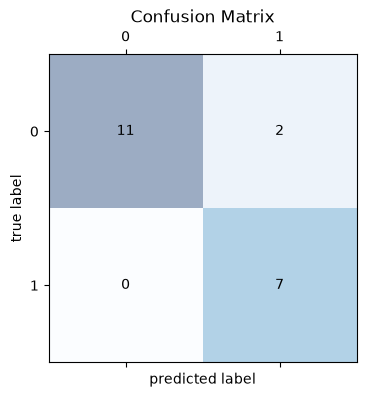

Accuracy score: 0.9


In [26]:
assert predictions.size == 20
assert hashlib.sha256(json.dumps(model.get_params()).encode()).hexdigest() == \
'92f8858316e0ad22d4eaa3f686a7bd9f171c7d2a48c2e17144bbf4c73bf0123d', 'Have you fitted the correct model?'
plot_confusion_matrix(y_test, predictions)

print ('Accuracy score:', accuracy_score(y_test, predictions)) 

Our model is not performing bad at all! If you want to improve it, you should make **small alterations**, **one at a time**! Keeping track of your changes is crucial to know exactly what change is helping or hurting your model! 

## Exercise 4 - Pipelines!!!!! 

We've already loaded and splitted a dataset for the following exercises. They're stored in the `new_X_train`, `new_X_test`, `new_y_train` and `new_y_test` variables.

In a perfect world, where you have all your data clean and ready-to-go, you can create your pipeline with just Scikit-learn's Transformers. However, in the real world, that's not the case, and you'll need to create custom Transformers to get the job done. Take a look at the data set, what do you see?

In [27]:
new_X, new_y = get_dataset()  # preloaded dataset
new_X_train, new_X_test, new_y_train, new_y_test = train_test_split(new_X, new_y, test_size=0.33)

In [28]:
display(new_X)

,17,leg_1,7,arm_2,2,11,4,16,0,14,...,12,10,15,9,19,18,8,6,arm_0,1
0,-0.334501,lee,-0.653329,Betsey,-0.474945,2.143944,0.504987,-0.792521,NaN,0.633919,...,1.765454,-0.071335,0.087142,-0.661786,-1.200296,0.865755,0.186454,0.404982,tribesman,0.029102
1,1.375707,Runge,0.125576,bottleneck,-0.150056,0.321357,NaN,1.189470,1.613711,0.421921,...,-0.173072,-1.158068,0.963360,-0.244157,-0.297564,0.701173,0.453534,0.015579,sloven,0.659924
2,1.189017,Hackett,-0.570746,neuropsychiatric,1.420504,-1.122722,-0.623141,-0.637740,NaN,0.382410,...,-0.832356,-0.270624,-1.692005,0.289169,-0.637387,-0.555477,0.492451,0.471416,Shakespearian,0.950573
3,-0.689188,woodchuck,0.197911,systematic,1.735964,0.059630,1.317394,1.049553,0.698223,-0.646937,...,-0.651418,0.852392,-1.106450,0.895193,2.075261,0.197600,0.393485,-0.483886,semper,-0.320670
4,-0.968344,inkling,-1.334025,kingpin,0.105376,-0.988591,-0.982487,-0.989628,0.179894,-1.103589,...,-0.601368,-0.348985,1.303736,0.918317,0.550052,-0.224633,1.392002,0.319782,compensable,-0.222100
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,1.755341,scarface,0.971571,ephemeris,-0.248964,0.711615,1.179297,1.551152,-1.534114,-1.124642,...,0.645376,-1.217220,-0.763516,0.332314,2.060748,0.067518,1.277677,1.368632,antebellum,1.431401
96,0.640843,epithelial,0.572583,culminate,-0.571179,1.503398,-1.001620,-0.247177,-0.220964,0.877362,...,1.399355,1.039670,-0.977637,0.208383,1.797687,-0.281100,0.026886,0.924634,irresolution,-0.545612
97,-0.309172,cutler,-0.478749,experiment,0.222134,-1.081057,0.096121,0.938284,-0.039555,1.053153,...,1.255756,1.985223,-0.511036,0.028318,-0.434496,-0.462275,0.681501,-0.894607,delectate,-1.604993
98,-0.305225,inveigle,-0.186971,nod,-0.609512,0.028181,0.010353,1.390208,1.085896,-0.009119,...,0.056650,-1.648321,0.735948,-0.025027,-1.065114,-1.311836,0.474698,0.529693,zag,1.203166


As you can see, it's the exact same dataset from the previous exercises! The same issues have returned:

- There are 4 columns whose name starts with either arm or leg which are all filled with gibberish.
- There are some missing values in some columns.

So, first things first, let's get rid of those columns with gibberish through a **Custom Transformer**, so we can plug it in a Scikit Pipeline after.

### Exercise 4.1 - Custom Transformer

In [29]:
# Create a pipeline step called RemoveLimbs that removes any
# column whose name starts with the string 'arm' or ´leg´

# YOUR CODE HERE
class RemoveLimbs(TransformerMixin):
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        return X.loc[:, ~X.columns.str.startswith(('arm', 'leg'))]

In [30]:
new_X, new_y = get_dataset()  # preloaded dataset
new_X_train, new_X_test, new_y_train, new_y_test = train_test_split(new_X, new_y, test_size=0.33)
assert issubclass(RemoveLimbs, TransformerMixin)
assert hashlib.sha256(json.dumps(''.join(sorted(RemoveLimbs().fit_transform(new_X).columns))).encode()).hexdigest() == \
'258dfdcebee87cef91291a45e5020f6bb7abe504edb66a1f68b5cb853068bb0a', 'The transformer does not work as expected.'

### Exercise 4.2 - Pipelines are the best!

Now that we have our Custom Transformer in place, we can design our pipeline! 

Create a pipeline with the following steps:

1. Removes limbs columns
2. Imputes missing values with the mean
3. Has a Random Forest Classifier as the last step

Use `make_pipeline` to create your pipeline with as many steps as you want as long as the first two are the Custom Transformer you developed previously, a `SimpleImputer` as the second step, and a `RandomForestClassifier` as the last step. Save your pipeline into a variable named `pipeline`!

In [31]:
# pipeline = make_pipeline(...)
# YOUR CODE HERE
pipeline = make_pipeline(RemoveLimbs(), SimpleImputer(), RandomForestClassifier())

In [32]:
assert hashlib.sha256(json.dumps(pipeline.steps[0][0]).encode()).hexdigest() == \
'617c9c17cb0d8631f14cbb249c4a1bf179e2a914fe58e2fb9bdb7f66767ec388', 'The first pipeline step is not correct.'
assert hashlib.sha256(json.dumps(pipeline.steps[1][0]).encode()).hexdigest() == \
'78f213811c43cb005d721596ad15f98a02e57c6db473e2a80b3904837b3a998a', 'The second pipeline step is not correct.'
assert hashlib.sha256(json.dumps(pipeline.steps[-1][0]).encode()).hexdigest() == \
'8be548c26fc993261b503615ee03e07c5a6054dfa558b41c5e1fd836fceb155c', 'The last pipeline step is not correct.'

Does it work? Let's check it out on our dataset!

In [33]:
pipeline.fit(new_X_train, new_y_train)
new_y_pred = pipeline.predict(new_X_test)
accuracy_score(new_y_test, new_y_pred)

0.9090909090909091

It doesn't get much simpler that this, does it?

For an extra challenge, go back to exercises 2 and 3 and follow our workflow but with a Pipeline! For each special processing we've done, you can create a custom transformer for that column.

Dominating pipelines and custom transformers can be a huge time saver! And there's the hackathon ahead...

**Good luck!**